In [66]:
#!/usr/bin/env python3
"""
COMPLETE WORKING PIPELINE: Music Emotion Recognition
Corrected paths for Kaggle DEAM dataset
"""

# ============================================================================
# 1. IMPORTS & SETUP
# ============================================================================

import os
import sys
import numpy as np
import pandas as pd
import librosa
import librosa.display
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

print("=" * 70)
print("MUSIC EMOTION RECOGNITION - COMPLETE PIPELINE")
print("=" * 70)

MUSIC EMOTION RECOGNITION - COMPLETE PIPELINE


In [67]:

class Config:
    """Configuration parameters"""
    
    # KAGGLE PATHS
    BASE_DIR = '/kaggle/input/deam-dataset'
    
    # AUDIO PATHS
    AUDIO_DIR = BASE_DIR + '/DEAM_datasets/MEMD_audio'
    
    # ANNOTATION PATHS - PER-RATER ANNOTATIONS
    ANNOTATIONS_DIR = BASE_DIR + '/DEAM_datasets/DEAM_Annotations/annotations per each rater/dynamic (per second annotations)'
    AROUSAL_ANNOTATIONS_DIR = ANNOTATIONS_DIR + '/arousal'
    VALENCE_ANNOTATIONS_DIR = ANNOTATIONS_DIR + '/valence'
    
    # AUDIO PARAMETERS
    SAMPLE_RATE = 16000
    SEGMENT_DURATION = 5  # seconds
    SEGMENT_SAMPLES = SAMPLE_RATE * SEGMENT_DURATION
    
    # FEATURE EXTRACTION
    N_MELS = 128
    N_FFT = 2048
    HOP_LENGTH = 512
    
    # MODEL PARAMETERS
    BATCH_SIZE = 32
    EPOCHS = 30
    LEARNING_RATE = 0.001
    DROPOUT_RATE = 0.3
    
    # DATA SIZING
    MAX_SONGS = 200  # Process 200 songs
    TEST_SIZE = 0.2
    VAL_SIZE = 0.1
    
    # OUTPUT
    OUTPUT_DIR = '/kaggle/working/'
    MODEL_SAVE_PATH = '/kaggle/working/best_fusion_model.pth'
    
    # EMOTION CLASSES (Russell's Circumplex Model)
    EMOTION_MAP = {
        0: 'Energetic/Happy',      # High Valence, High Arousal
        1: 'Calm/Relaxing',        # High Valence, Low Arousal
        2: 'Angry/Tense',          # Low Valence, High Arousal
        3: 'Sad/Depressing'        # Low Valence, Low Arousal
    }
    
    # EMOTION COLORS for visualization
    EMOTION_COLORS = {
        0: '#FF6B6B',  # Red - Energetic
        1: '#4ECDC4',  # Teal - Calm
        2: '#FFD166',  # Yellow - Angry
        3: '#6A0572'   # Purple - Sad
    }

# Create output directory
os.makedirs(Config.OUTPUT_DIR, exist_ok=True)

In [68]:
# ============================================================================
# 3. DATA LOADER - CORRECTED FOR 10-TIME-POINT ANNOTATIONS
# ============================================================================

class DEAMDataLoader:
    """Data loader that correctly processes 10-time-point annotations"""
    
    def __init__(self):
        print("Initializing DEAM Data Loader...")
        print("-" * 50)
        
        # Check paths
        self._check_paths()
        
        # Initialize paths
        self.audio_dir = Config.AUDIO_DIR
        self.arousal_dir = Config.AROUSAL_ANNOTATIONS_DIR
        self.valence_dir = Config.VALENCE_ANNOTATIONS_DIR
        self.sample_rate = Config.SAMPLE_RATE
        self.segment_samples = Config.SEGMENT_SAMPLES
        
        # Load data
        self._load_data()
        
        # Create song mapping
        self.song_mapping = self._create_song_mapping()
        print(f"\n✅ Created mapping for {len(self.song_mapping)} songs")
        
        # Analyze sample annotation
        self._analyze_annotations()
    
    def _check_paths(self):
        """Check if all required paths exist"""
        print("Checking paths...")
        
        paths_to_check = [
            ("Audio directory", Config.AUDIO_DIR),
            ("Arousal annotations", Config.AROUSAL_ANNOTATIONS_DIR),
            ("Valence annotations", Config.VALENCE_ANNOTATIONS_DIR)
        ]
        
        all_paths_exist = True
        for name, path in paths_to_check:
            exists = os.path.exists(path)
            print(f"  {name:25} {path}")
            print(f"  {'Exists:':27} {exists}")
            if not exists:
                all_paths_exist = False
        
        if not all_paths_exist:
            print("\n❌ ERROR: Some required paths don't exist!")
            sys.exit(1)
    
    def _load_data(self):
        """Load MP3 files and annotation CSVs"""
        print("\nLoading data...")
        
        # Load MP3 files
        self.mp3_files = sorted([f for f in os.listdir(self.audio_dir) 
                                if f.lower().endswith('.mp3')])
        print(f"  ✓ Found {len(self.mp3_files)} MP3 files")
        
        # Load arousal annotation files
        self.arousal_csv_files = sorted([f for f in os.listdir(self.arousal_dir) 
                                        if f.endswith('.csv')])
        print(f"  ✓ Found {len(self.arousal_csv_files)} arousal annotation files")
        
        # Load valence annotation files
        self.valence_csv_files = sorted([f for f in os.listdir(self.valence_dir) 
                                        if f.endswith('.csv')])
        print(f"  ✓ Found {len(self.valence_csv_files)} valence annotation files")
        
        # Show samples
        print(f"\n  Sample MP3 files: {self.mp3_files[:3]}...")
        print(f"  Sample arousal files: {self.arousal_csv_files[:3]}...")
        print(f"  Sample valence files: {self.valence_csv_files[:3]}...")
    
    def _create_song_mapping(self):
        """Create mapping between MP3 files and annotation files"""
        print("\nCreating song mapping...")
        
        mapping = {}
        successful_matches = 0
        
        # Process MP3 files
        for mp3_file in self.mp3_files[:Config.MAX_SONGS * 2]:  # Look at more files
            # Extract song ID from MP3 filename
            import re
            numbers = re.findall(r'\d+', mp3_file)
            if not numbers:
                continue
            
            song_id = int(numbers[0])
            
            # Find corresponding annotation files
            arousal_csv = None
            valence_csv = None
            
            # Pattern 1: Exact number match
            arousal_patterns = [f"{song_id}.csv", f"song_{song_id}.csv", f"Song_{song_id}.csv"]
            valence_patterns = [f"{song_id}.csv", f"song_{song_id}.csv", f"Song_{song_id}.csv"]
            
            for pattern in arousal_patterns:
                if pattern in self.arousal_csv_files:
                    arousal_csv = pattern
                    break
            
            for pattern in valence_patterns:
                if pattern in self.valence_csv_files:
                    valence_csv = pattern
                    break
            
            # Pattern 2: Find by number in filename
            if not arousal_csv:
                for csv_file in self.arousal_csv_files:
                    csv_numbers = re.findall(r'\d+', csv_file)
                    if csv_numbers and int(csv_numbers[0]) == song_id:
                        arousal_csv = csv_file
                        break
            
            if not valence_csv:
                for csv_file in self.valence_csv_files:
                    csv_numbers = re.findall(r'\d+', csv_file)
                    if csv_numbers and int(csv_numbers[0]) == song_id:
                        valence_csv = csv_file
                        break
            
            if arousal_csv and valence_csv:
                mapping[song_id] = {
                    'mp3_file': mp3_file,
                    'arousal_csv': arousal_csv,
                    'valence_csv': valence_csv
                }
                successful_matches += 1
        
        print(f"  Matched {successful_matches} songs")
        return mapping
    
    def _analyze_annotations(self):
        """Analyze annotation CSV structure"""
        if not self.song_mapping:
            print("⚠️ No songs mapped, skipping annotation analysis")
            return
        
        # Get first song
        first_song_id = list(self.song_mapping.keys())[0]
        song_info = self.song_mapping[first_song_id]
        
        arousal_path = os.path.join(self.arousal_dir, song_info['arousal_csv'])
        valence_path = os.path.join(self.valence_dir, song_info['valence_csv'])
        
        print("\nAnalyzing annotation CSV structure...")
        
        try:
            # Load arousal CSV
            arousal_df = pd.read_csv(arousal_path)
            print(f"  Arousal CSV shape: {arousal_df.shape}")
            print(f"  Columns: {list(arousal_df.columns)}")
            
            # Check time columns
            time_cols = [col for col in arousal_df.columns if 'sample_' in col]
            print(f"  Time columns: {len(time_cols)}")
            print(f"  Time range: {time_cols[0]} to {time_cols[-1]}")
            
            # Check number of raters
            print(f"  Number of raters (rows): {len(arousal_df)}")
            
            # Show sample values
            print(f"\n  Sample values (first rater):")
            for col in time_cols[:3]:
                print(f"    {col}: {arousal_df[col].iloc[0]:.3f}")
            
        except Exception as e:
            print(f"  Error analyzing CSV: {e}")
    
    def get_available_songs(self):
        """Get list of available song IDs"""
        return sorted(list(self.song_mapping.keys()))
    
    def load_audio(self, song_id):
        """Load audio for a song"""
        if song_id not in self.song_mapping:
            return None
        
        mp3_file = self.song_mapping[song_id]['mp3_file']
        mp3_path = os.path.join(self.audio_dir, mp3_file)
        
        try:
            # Load first 45 seconds of audio
            audio, sr = librosa.load(
                mp3_path,
                sr=self.sample_rate,
                mono=True,
                duration=45
            )
            return audio
        except Exception as e:
            print(f"  Error loading {mp3_file}: {e}")
            return None
    
    def load_annotations(self, song_id):
        """Load and process annotations for a song"""
        if song_id not in self.song_mapping:
            return None, None
        
        song_info = self.song_mapping[song_id]
        arousal_path = os.path.join(self.arousal_dir, song_info['arousal_csv'])
        valence_path = os.path.join(self.valence_dir, song_info['valence_csv'])
        
        try:
            # Load CSV files
            arousal_df = pd.read_csv(arousal_path)
            valence_df = pd.read_csv(valence_path)
            
            # Process annotations
            arousal_series = self._process_annotation_csv(arousal_df)
            valence_series = self._process_annotation_csv(valence_df)
            
            return valence_series, arousal_series
            
        except Exception as e:
            print(f"  Error loading annotations for song {song_id}: {e}")
            return None, None
    
    def _process_annotation_csv(self, df):
        """
        Process annotation CSV with 10 time points (15s to 19.5s)
        Steps:
        1. Extract time columns (sample_15000ms, etc.)
        2. Average across all raters for each time point
        3. Interpolate from 10 points to 45 seconds
        """
        # Extract time columns
        time_cols = [col for col in df.columns if 'sample_' in col]
        
        if not time_cols:
            raise ValueError("No time columns found in CSV")
        
        # Extract time points in milliseconds
        import re
        time_points_ms = []
        for col in time_cols:
            numbers = re.findall(r'\d+', col)
            if numbers:
                time_points_ms.append(int(numbers[0]))
        
        # Sort by time
        sorted_indices = np.argsort(time_points_ms)
        time_points_ms = np.array(time_points_ms)[sorted_indices]
        time_cols = np.array(time_cols)[sorted_indices]
        
        # Average across raters for each time point
        time_series = []
        for col in time_cols:
            avg_value = df[col].mean()
            time_series.append(avg_value)
        
        time_series = np.array(time_series)
        
        # Convert time from milliseconds to seconds
        time_points_seconds = time_points_ms / 1000.0
        
        # Original data: 10 points from 15s to 19.5s (every 0.5s)
        # We need: 45 points from 0s to 44s (every 1s)
        
        # Create target time points (0 to 44 seconds, 1 second intervals)
        target_times = np.arange(0, 45, 1.0)
        
        # Linear interpolation
        interpolated_values = np.interp(target_times, time_points_seconds, time_series)
        
        return interpolated_values
    
    def vad_to_emotion(self, valence, arousal):
        """Convert valence-arousal to emotion class"""
        if valence > 0 and arousal > 0:
            return 0  # Energetic/Happy
        elif valence > 0 and arousal <= 0:
            return 1  # Calm/Relaxing
        elif valence <= 0 and arousal > 0:
            return 2  # Angry/Tense
        else:
            return 3  # Sad/Depressing
    
    def prepare_dataset(self, max_songs=None):
        """Prepare complete dataset"""
        print("\n" + "="*80)
        print("PREPARING DATASET")
        print("="*80)
        
        # Get songs to process
        available_songs = self.get_available_songs()
        if max_songs:
            songs_to_process = available_songs[:max_songs]
        else:
            songs_to_process = available_songs
        
        print(f"Processing {len(songs_to_process)} songs...")
        print(f"Each song: 45 seconds → 9 segments of 5 seconds")
        
        all_segments = []
        all_labels = []
        all_valence = []
        all_arousal = []
        all_song_ids = []
        
        processed_songs = 0
        total_segments = 0
        
        for i, song_id in enumerate(songs_to_process):
            # Progress update
            if i % 10 == 0 and i > 0:
                print(f"  Processed {i}/{len(songs_to_process)} songs...")
            
            # Load audio
            audio = self.load_audio(song_id)
            if audio is None:
                continue
            
            # Load annotations
            valence_series, arousal_series = self.load_annotations(song_id)
            if valence_series is None:
                continue
            
            # Create segments
            num_segments = min(len(audio) // self.segment_samples, 9)
            
            for seg_idx in range(num_segments):
                # Extract audio segment
                start = seg_idx * self.segment_samples
                end = (seg_idx + 1) * self.segment_samples
                segment = audio[start:end]
                
                # Pad if necessary
                if len(segment) < self.segment_samples:
                    segment = np.pad(segment, (0, self.segment_samples - len(segment)))
                
                # Calculate segment-level valence/arousal
                seg_valence = np.mean(valence_series[seg_idx*5:(seg_idx+1)*5])
                seg_arousal = np.mean(arousal_series[seg_idx*5:(seg_idx+1)*5])
                
                # Convert to emotion
                emotion = self.vad_to_emotion(seg_valence, seg_arousal)
                
                # Store data
                all_segments.append(segment)
                all_labels.append(emotion)
                all_valence.append(seg_valence)
                all_arousal.append(seg_arousal)
                all_song_ids.append(song_id)
                total_segments += 1
            
            processed_songs += 1
        
        # Convert to numpy arrays
        if len(all_segments) == 0:
            print("\n❌ ERROR: No segments created!")
            return self._create_dummy_dataset()
        
        all_segments = np.array(all_segments, dtype=np.float32)
        all_labels = np.array(all_labels, dtype=np.int64)
        all_valence = np.array(all_valence, dtype=np.float32)
        all_arousal = np.array(all_arousal, dtype=np.float32)
        all_song_ids = np.array(all_song_ids, dtype=np.int64)
        
        # Dataset statistics
        print(f"\n" + "="*80)
        print("DATASET STATISTICS")
        print("="*80)
        print(f"✅ Successfully processed {processed_songs} songs")
        print(f"✅ Created {total_segments} segments")
        print(f"✅ Audio shape: {all_segments.shape}")
        print(f"   - Each segment: {all_segments.shape[1]} samples")
        print(f"   - Duration: {all_segments.shape[1]/Config.SAMPLE_RATE:.1f} seconds")
        
        # Class distribution
        unique_labels, counts = np.unique(all_labels, return_counts=True)
        print(f"\n📊 CLASS DISTRIBUTION:")
        for label, count in zip(unique_labels, counts):
            emotion_name = Config.EMOTION_MAP[label]
            percentage = 100 * count / len(all_labels)
            color = Config.EMOTION_COLORS[label]
            print(f"   {emotion_name:20} {count:4d} segments ({percentage:5.1f}%)")
        
        # Valence/Arousal statistics
        print(f"\n📈 VALENCE/AROUSAL STATISTICS:")
        print(f"   Valence - Mean: {np.mean(all_valence):.3f} ± {np.std(all_valence):.3f}")
        print(f"            Min: {np.min(all_valence):.3f}, Max: {np.max(all_valence):.3f}")
        print(f"   Arousal - Mean: {np.mean(all_arousal):.3f} ± {np.std(all_arousal):.3f}")
        print(f"            Min: {np.min(all_arousal):.3f}, Max: {np.max(all_arousal):.3f}")
        
        return all_segments, all_labels, all_valence, all_arousal, all_song_ids
    
    def _create_dummy_dataset(self):
        """Create dummy dataset for testing"""
        print("Creating dummy dataset for testing...")
        
        num_segments = 180  # 20 songs * 9 segments
        segment_length = Config.SEGMENT_SAMPLES
        
        all_segments = []
        all_labels = []
        
        for i in range(num_segments):
            # Create synthetic audio (pink noise)
            segment = np.random.randn(segment_length).astype(np.float32) * 0.1
            
            # Apply some structure
            t = np.linspace(0, 1, segment_length)
            segment += 0.05 * np.sin(2 * np.pi * 440 * t)  # Add 440Hz tone
            
            # Assign emotion based on segment number
            emotion = i % 4
            
            all_segments.append(segment)
            all_labels.append(emotion)
        
        all_segments = np.array(all_segments, dtype=np.float32)
        all_labels = np.array(all_labels, dtype=np.int64)
        
        # Create synthetic valence/arousal
        all_valence = np.random.randn(len(all_labels)).astype(np.float32) * 0.5
        all_arousal = np.random.randn(len(all_labels)).astype(np.float32) * 0.5
        all_song_ids = np.repeat(np.arange(20), 9)[:len(all_labels)]
        
        print(f"Created dummy dataset with {len(all_segments)} segments")
        
        return all_segments, all_labels, all_valence, all_arousal, all_song_ids

In [69]:
# ============================================================================
# 4. FEATURE EXTRACTOR
# ============================================================================

class FeatureExtractor:
    """Extracts spectral and HuBERT features"""
    
    def __init__(self):
        self.sample_rate = Config.SAMPLE_RATE
        self.n_mels = Config.N_MELS
        self.n_fft = Config.N_FFT
        self.hop_length = Config.HOP_LENGTH
        
        # Initialize HuBERT model
        self.hubert_processor = None
        self.hubert_model = None
        
        print("Feature Extractor initialized")
    
    def _init_hubert(self):
        """Initialize HuBERT model"""
        if self.hubert_processor is None:
            try:
                print("Loading HuBERT model...")
                from transformers import Wav2Vec2FeatureExtractor, HubertModel
                
                # Use base model for faster processing
                self.hubert_processor = Wav2Vec2FeatureExtractor.from_pretrained(
                    "facebook/hubert-base-ls960"
                )
                self.hubert_model = HubertModel.from_pretrained(
                    "facebook/hubert-base-ls960"
                )
                self.hubert_model.eval()  # Freeze model
                
                print("✅ HuBERT model loaded successfully")
                
            except Exception as e:
                print(f"⚠️ Could not load HuBERT: {e}")
                print("Will use spectral features only")
    
    def extract_mel_spectrogram(self, audio_segment):
        """Extract Mel-spectrogram from audio"""
        # Ensure correct length
        if len(audio_segment) != Config.SEGMENT_SAMPLES:
            if len(audio_segment) > Config.SEGMENT_SAMPLES:
                audio_segment = audio_segment[:Config.SEGMENT_SAMPLES]
            else:
                audio_segment = np.pad(audio_segment, 
                                     (0, Config.SEGMENT_SAMPLES - len(audio_segment)))
        
        # Compute Mel-spectrogram
        mel_spec = librosa.feature.melspectrogram(
            y=audio_segment,
            sr=self.sample_rate,
            n_mels=self.n_mels,
            n_fft=self.n_fft,
            hop_length=self.hop_length,
            power=2.0
        )
        
        # Convert to log scale (dB)
        log_mel = librosa.power_to_db(mel_spec, ref=np.max)
        
        # Normalize to [0, 1]
        log_mel = (log_mel - log_mel.min()) / (log_mel.max() - log_mel.min() + 1e-8)
        
        # Add channel dimension
        log_mel = np.expand_dims(log_mel, axis=0)
        
        return log_mel
    
    def extract_hubert_features(self, audio_segment):
        """Extract HuBERT embeddings"""
        self._init_hubert()
        
        if self.hubert_model is None:
            # Return dummy features if HuBERT not available
            return np.zeros(768, dtype=np.float32)
        
        # Prepare audio for HuBERT
        audio_input = audio_segment.astype(np.float32)
        
        try:
            # Process with HuBERT
            inputs = self.hubert_processor(
                audio_input,
                sampling_rate=self.sample_rate,
                return_tensors="pt",
                padding=True
            )
            
            # Extract features
            with torch.no_grad():
                outputs = self.hubert_model(**inputs)
                # Average over time dimension
                features = torch.mean(outputs.last_hidden_state, dim=1)
            
            return features.squeeze().cpu().numpy()
            
        except Exception as e:
            print(f"Error extracting HuBERT features: {e}")
            return np.zeros(768, dtype=np.float32)
    
    def extract_all_features(self, audio_segment):
        """Extract both Mel-spectrogram and HuBERT features"""
        spectral = self.extract_mel_spectrogram(audio_segment)
        hubert = self.extract_hubert_features(audio_segment)
        
        return spectral, hubert


In [70]:
# ============================================================================
# 5. MODEL ARCHITECTURES
# ============================================================================

class CNNBranch(nn.Module):
    """CNN branch for processing spectrograms"""
    
    def __init__(self):
        super(CNNBranch, self).__init__()
        
        # Spectrogram input: (batch, 1, 128, 431) for 5 seconds at 16kHz
        
        # CNN layers
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool1 = nn.MaxPool2d(2)
        
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool2 = nn.MaxPool2d(2)
        
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool3 = nn.MaxPool2d(2)
        
        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(256)
        self.pool4 = nn.MaxPool2d(2)
        
        # Adaptive pooling to handle variable sizes
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))
        
        # Fully connected layers
        self.fc1 = nn.Linear(256 * 4 * 4, 512)
        self.dropout1 = nn.Dropout(Config.DROPOUT_RATE)
        self.fc2 = nn.Linear(512, 256)
        
    def forward(self, x):
        # x shape: (batch, 1, n_mels, time_frames)
        
        # CNN layers with ReLU and pooling
        x = self.pool1(F.relu(self.bn1(self.conv1(x))))
        x = self.pool2(F.relu(self.bn2(self.conv2(x))))
        x = self.pool3(F.relu(self.bn3(self.conv3(x))))
        x = self.pool4(F.relu(self.bn4(self.conv4(x))))
        
        # Adaptive pooling
        x = self.adaptive_pool(x)
        
        # Flatten
        x = x.view(x.size(0), -1)
        
        # Fully connected layers
        x = F.relu(self.fc1(x))
        x = self.dropout1(x)
        x = self.fc2(x)
        
        return x

class HuBERTBranch(nn.Module):
    """MLP branch for processing HuBERT embeddings"""
    
    def __init__(self, input_dim=768):
        super(HuBERTBranch, self).__init__()
        
        self.fc1 = nn.Linear(input_dim, 512)
        self.bn1 = nn.BatchNorm1d(512)
        self.dropout1 = nn.Dropout(Config.DROPOUT_RATE)
        
        self.fc2 = nn.Linear(512, 256)
        self.bn2 = nn.BatchNorm1d(256)
        
    def forward(self, x):
        # x shape: (batch, hubert_dim)
        
        x = F.relu(self.bn1(self.fc1(x)))
        x = self.dropout1(x)
        x = F.relu(self.bn2(self.fc2(x)))
        
        return x

class FusionModel(nn.Module):
    """Fusion model combining CNN and HuBERT branches"""
    
    def __init__(self, num_classes=4):
        super(FusionModel, self).__init__()
        
        # Individual branches
        self.cnn_branch = CNNBranch()
        self.hubert_branch = HuBERTBranch()
        
        # Fusion layers
        # CNN output: 256, HuBERT output: 256 → Total: 512
        self.fusion_fc1 = nn.Linear(512, 256)
        self.bn_fusion = nn.BatchNorm1d(256)
        self.dropout_fusion = nn.Dropout(Config.DROPOUT_RATE)
        
        self.fusion_fc2 = nn.Linear(256, 128)
        self.fusion_fc3 = nn.Linear(128, num_classes)
        
        print(f"Fusion Model initialized with {num_classes} classes")
    
    def forward(self, spectral_input, hubert_input):
        # Process through individual branches
        cnn_features = self.cnn_branch(spectral_input)      # (batch, 256)
        hubert_features = self.hubert_branch(hubert_input)  # (batch, 256)
        
        # Concatenate features
        fused_features = torch.cat([cnn_features, hubert_features], dim=1)
        
        # Fusion layers
        x = F.relu(self.bn_fusion(self.fusion_fc1(fused_features)))
        x = self.dropout_fusion(x)
        x = F.relu(self.fusion_fc2(x))
        x = self.fusion_fc3(x)  # (batch, num_classes)
        
        return x
    
    def count_parameters(self):
        """Count total and trainable parameters"""
        total_params = sum(p.numel() for p in self.parameters())
        trainable_params = sum(p.numel() for p in self.parameters() if p.requires_grad)
        return total_params, trainable_params

In [71]:
# ============================================================================
# 6. DATASET CLASS
# ============================================================================

class MusicEmotionDataset(Dataset):
    """PyTorch Dataset for music emotion recognition"""
    
    def __init__(self, segments, labels, feature_extractor, extract_features=True):
        """
        Args:
            segments: List of audio segments
            labels: List of emotion labels
            feature_extractor: FeatureExtractor instance
            extract_features: Whether to pre-extract features
        """
        self.segments = segments
        self.labels = labels
        self.feature_extractor = feature_extractor
        
        if extract_features:
            print("Extracting features...")
            self.spectral_features = []
            self.hubert_features = []
            
            for i, segment in enumerate(segments):
                spectral, hubert = feature_extractor.extract_all_features(segment)
                self.spectral_features.append(spectral)
                self.hubert_features.append(hubert)
                
                # Progress update
                if i % 100 == 0 and i > 0:
                    print(f"  Extracted features for {i}/{len(segments)} segments")
            
            # Convert to numpy arrays
            self.spectral_features = np.array(self.spectral_features, dtype=np.float32)
            self.hubert_features = np.array(self.hubert_features, dtype=np.float32)
            
            print(f"✅ Feature extraction complete")
            print(f"   Spectral features shape: {self.spectral_features.shape}")
            print(f"   HuBERT features shape: {self.hubert_features.shape}")
        else:
            # Extract features on-the-fly
            self.spectral_features = None
            self.hubert_features = None
    
    def __len__(self):
        return len(self.labels)
    
    def __getitem__(self, idx):
        if self.spectral_features is not None:
            # Use pre-extracted features
            spectral = self.spectral_features[idx]
            hubert = self.hubert_features[idx]
        else:
            # Extract features on-the-fly
            segment = self.segments[idx]
            spectral, hubert = self.feature_extractor.extract_all_features(segment)
        
        label = self.labels[idx]
        
        # Convert to tensors
        spectral_tensor = torch.FloatTensor(spectral)
        hubert_tensor = torch.FloatTensor(hubert)
        label_tensor = torch.LongTensor([label])[0]
        
        return spectral_tensor, hubert_tensor, label_tensor

In [72]:
# ============================================================================
# 7. TRAINER CLASS
# ============================================================================

class Trainer:
    """Handles model training and evaluation"""
    
    def __init__(self, model, device=None):
        if device is None:
            self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        else:
            self.device = device
        
        self.model = model.to(self.device)
        self.criterion = nn.CrossEntropyLoss()
        
        print(f"Training on device: {self.device}")
    
    def train_epoch(self, dataloader, optimizer, epoch_num):
        """Train for one epoch"""
        self.model.train()
        total_loss = 0
        correct = 0
        total = 0
        
        for batch_idx, (spectral, hubert, labels) in enumerate(dataloader):
            # Move data to device
            spectral = spectral.to(self.device)
            hubert = hubert.to(self.device)
            labels = labels.to(self.device)
            
            # Zero gradients
            optimizer.zero_grad()
            
            # Forward pass
            outputs = self.model(spectral, hubert)
            loss = self.criterion(outputs, labels)
            
            # Backward pass
            loss.backward()
            optimizer.step()
            
            # Statistics
            total_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
            
            # Print progress
            if batch_idx % 20 == 0:
                batch_acc = 100. * correct / total if total > 0 else 0
                print(f"  Batch {batch_idx:3d}/{len(dataloader)} | "
                      f"Loss: {loss.item():.4f} | Acc: {batch_acc:6.2f}%")
        
        # Calculate epoch statistics
        epoch_loss = total_loss / len(dataloader)
        epoch_acc = 100. * correct / total
        
        return epoch_loss, epoch_acc
    
    def evaluate(self, dataloader):
        """Evaluate model"""
        self.model.eval()
        total_loss = 0
        correct = 0
        total = 0
        all_predictions = []
        all_labels = []
        
        with torch.no_grad():
            for spectral, hubert, labels in dataloader:
                # Move data to device
                spectral = spectral.to(self.device)
                hubert = hubert.to(self.device)
                labels = labels.to(self.device)
                
                # Forward pass
                outputs = self.model(spectral, hubert)
                loss = self.criterion(outputs, labels)
                
                # Statistics
                total_loss += loss.item()
                _, predicted = outputs.max(1)
                total += labels.size(0)
                correct += predicted.eq(labels).sum().item()
                
                # Store for metrics
                all_predictions.extend(predicted.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
        
        # Calculate metrics
        avg_loss = total_loss / len(dataloader)
        accuracy = 100. * correct / total
        
        return avg_loss, accuracy, all_predictions, all_labels

In [73]:
# ============================================================================
# 8. VISUALIZATION
# ============================================================================

class Visualizer:
    """Visualization utilities"""
    
    @staticmethod
    def plot_training_history(history, save_path=None):
        """Plot training and validation curves"""
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        
        epochs = range(1, len(history['train_loss']) + 1)
        
        # Loss plot
        axes[0].plot(epochs, history['train_loss'], 'b-', linewidth=2, label='Training Loss')
        axes[0].plot(epochs, history['val_loss'], 'r-', linewidth=2, label='Validation Loss')
        axes[0].set_title('Training and Validation Loss', fontsize=14, fontweight='bold')
        axes[0].set_xlabel('Epoch', fontsize=12)
        axes[0].set_ylabel('Loss', fontsize=12)
        axes[0].legend(fontsize=11)
        axes[0].grid(True, alpha=0.3)
        
        # Accuracy plot
        axes[1].plot(epochs, history['train_acc'], 'b-', linewidth=2, label='Training Accuracy')
        axes[1].plot(epochs, history['val_acc'], 'r-', linewidth=2, label='Validation Accuracy')
        axes[1].set_title('Training and Validation Accuracy', fontsize=14, fontweight='bold')
        axes[1].set_xlabel('Epoch', fontsize=12)
        axes[1].set_ylabel('Accuracy (%)', fontsize=12)
        axes[1].legend(fontsize=11)
        axes[1].grid(True, alpha=0.3)
        
        # Learning rate plot
        axes[2].plot(epochs, history['learning_rate'], 'g-', linewidth=2, label='Learning Rate')
        axes[2].set_title('Learning Rate Schedule', fontsize=14, fontweight='bold')
        axes[2].set_xlabel('Epoch', fontsize=12)
        axes[2].set_ylabel('Learning Rate', fontsize=12)
        axes[2].set_yscale('log')
        axes[2].grid(True, alpha=0.3)
        
        plt.suptitle('Model Training History', fontsize=16, fontweight='bold', y=1.02)
        plt.tight_layout()
        
        if save_path:
            plt.savefig(save_path, dpi=150, bbox_inches='tight')
            print(f"✓ Saved training history to {save_path}")
        
        plt.show()
    
    @staticmethod
    def plot_confusion_matrix(y_true, y_pred, save_path=None):
        """Plot confusion matrix"""
        cm = confusion_matrix(y_true, y_pred)
        
        plt.figure(figsize=(10, 8))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=list(Config.EMOTION_MAP.values()),
                    yticklabels=list(Config.EMOTION_MAP.values()))
        plt.title('Confusion Matrix', fontsize=16, fontweight='bold')
        plt.ylabel('True Emotion', fontsize=12)
        plt.xlabel('Predicted Emotion', fontsize=12)
        plt.tight_layout()
        
        if save_path:
            plt.savefig(save_path, dpi=150, bbox_inches='tight')
            print(f"✓ Saved confusion matrix to {save_path}")
        
        plt.show()
    
    @staticmethod
    def plot_class_distribution(labels, save_path=None):
        """Plot class distribution"""
        unique, counts = np.unique(labels, return_counts=True)
        colors = [Config.EMOTION_COLORS[label] for label in unique]
        emotion_names = [Config.EMOTION_MAP[label] for label in unique]
        
        plt.figure(figsize=(10, 6))
        bars = plt.bar(emotion_names, counts, color=colors, edgecolor='black', linewidth=2)
        
        # Add count labels on bars
        for bar, count in zip(bars, counts):
            plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                    str(count), ha='center', va='bottom', fontsize=12, fontweight='bold')
        
        plt.title('Class Distribution in Dataset', fontsize=16, fontweight='bold')
        plt.xlabel('Emotion Class', fontsize=12)
        plt.ylabel('Number of Segments', fontsize=12)
        plt.grid(True, alpha=0.3, axis='y')
        
        if save_path:
            plt.savefig(save_path, dpi=150, bbox_inches='tight')
            print(f"✓ Saved class distribution to {save_path}")
        
        plt.show()
    
    @staticmethod
    def visualize_features(audio_segment, feature_extractor, save_path=None):
        """Visualize audio features"""
        # Extract features
        spectral, hubert = feature_extractor.extract_all_features(audio_segment)
        
        fig, axes = plt.subplots(2, 3, figsize=(15, 10))
        
        # 1. Audio waveform
        time_axis = np.arange(len(audio_segment)) / Config.SAMPLE_RATE
        axes[0, 0].plot(time_axis, audio_segment, color='blue', linewidth=1)
        axes[0, 0].set_title('Audio Waveform (5 seconds)', fontsize=12, fontweight='bold')
        axes[0, 0].set_xlabel('Time (seconds)')
        axes[0, 0].set_ylabel('Amplitude')
        axes[0, 0].grid(True, alpha=0.3)
        
        # 2. Mel-spectrogram
        im = axes[0, 1].imshow(spectral[0], aspect='auto', origin='lower', cmap='viridis')
        axes[0, 1].set_title('Mel-Spectrogram', fontsize=12, fontweight='bold')
        axes[0, 1].set_xlabel('Time Frames')
        axes[0, 1].set_ylabel('Mel Frequency Bands')
        plt.colorbar(im, ax=axes[0, 1])
        
        # 3. Frequency spectrum
        freqs = np.fft.rfftfreq(len(audio_segment), 1/Config.SAMPLE_RATE)
        spectrum = np.abs(np.fft.rfft(audio_segment))
        axes[0, 2].semilogy(freqs[:2000], spectrum[:2000], color='green', linewidth=1)
        axes[0, 2].set_title('Frequency Spectrum', fontsize=12, fontweight='bold')
        axes[0, 2].set_xlabel('Frequency (Hz)')
        axes[0, 2].set_ylabel('Magnitude')
        axes[0, 2].grid(True, alpha=0.3)
        
        # 4. HuBERT embeddings (first 50 dimensions)
        axes[1, 0].bar(range(min(50, len(hubert))), hubert[:50], color='orange', alpha=0.7)
        axes[1, 0].set_title('HuBERT Embeddings (First 50 Dimensions)', fontsize=12, fontweight='bold')
        axes[1, 0].set_xlabel('Dimension Index')
        axes[1, 0].set_ylabel('Embedding Value')
        axes[1, 0].grid(True, alpha=0.3)
        
        # 5. HuBERT embedding distribution
        axes[1, 1].hist(hubert, bins=50, color='purple', alpha=0.7, edgecolor='black')
        axes[1, 1].set_title('HuBERT Embeddings Distribution', fontsize=12, fontweight='bold')
        axes[1, 1].set_xlabel('Embedding Value')
        axes[1, 1].set_ylabel('Frequency')
        axes[1, 1].grid(True, alpha=0.3)
        
        # 6. Feature statistics
        feature_stats = pd.DataFrame({
            'Feature': ['Spectral Mean', 'Spectral Std', 'HuBERT Mean', 'HuBERT Std'],
            'Value': [spectral.mean(), spectral.std(), hubert.mean(), hubert.std()]
        })
        axes[1, 2].axis('off')
        axes[1, 2].text(0.1, 0.5, 
                       f"Spectral Features:\n"
                       f"  Mean: {spectral.mean():.4f}\n"
                       f"  Std: {spectral.std():.4f}\n"
                       f"  Shape: {spectral.shape}\n\n"
                       f"HuBERT Features:\n"
                       f"  Mean: {hubert.mean():.4f}\n"
                       f"  Std: {hubert.std():.4f}\n"
                       f"  Length: {len(hubert)}",
                       fontsize=11, fontfamily='monospace',
                       bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
        axes[1, 2].set_title('Feature Statistics', fontsize=12, fontweight='bold')
        
        plt.suptitle('Audio Feature Visualization', fontsize=16, fontweight='bold', y=1.02)
        plt.tight_layout()
        
        if save_path:
            plt.savefig(save_path, dpi=150, bbox_inches='tight')
            print(f"✓ Saved feature visualization to {save_path}")
        
        plt.show()


🎵 MUSIC EMOTION RECOGNITION SYSTEM
Using Spectral Features + HuBERT Embeddings

📦 Detected Kaggle environment
Installing required packages...

🚀 Starting complete pipeline...

🎵 STARTING COMPLETE PIPELINE

[STEP 1] LOADING DATA
----------------------------------------
Initializing DEAM Data Loader...
--------------------------------------------------
Checking paths...
  Audio directory           /kaggle/input/deam-dataset/DEAM_datasets/MEMD_audio
  Exists:                     True
  Arousal annotations       /kaggle/input/deam-dataset/DEAM_datasets/DEAM_Annotations/annotations per each rater/dynamic (per second annotations)/arousal
  Exists:                     True
  Valence annotations       /kaggle/input/deam-dataset/DEAM_datasets/DEAM_Annotations/annotations per each rater/dynamic (per second annotations)/valence
  Exists:                     True

Loading data...
  ✓ Found 1802 MP3 files
  ✓ Found 1802 arousal annotation files
  ✓ Found 1802 valence annotation files

  Sample MP3

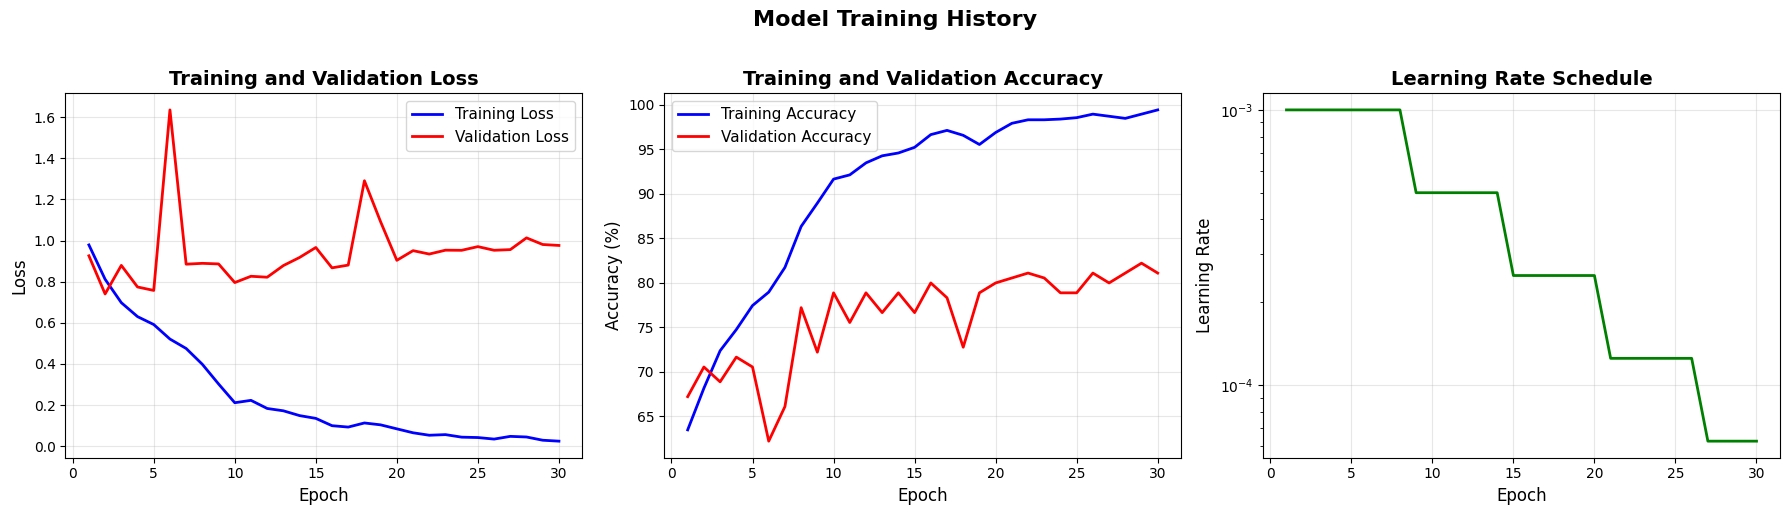

✓ Saved confusion matrix to /kaggle/working/confusion_matrix.png


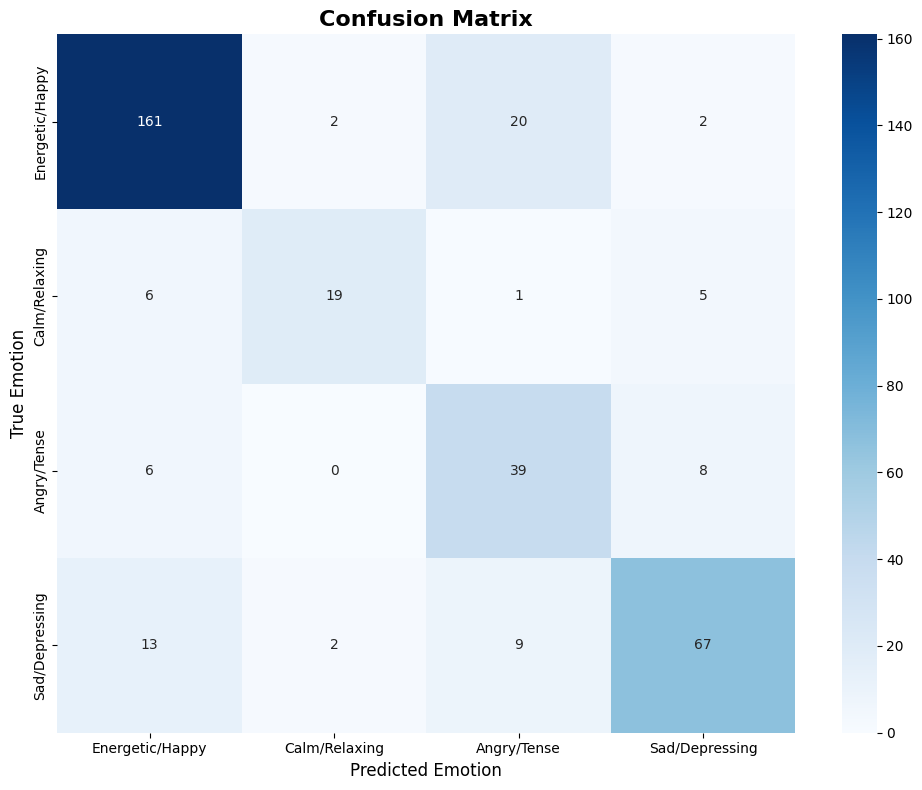

✓ Saved class distribution to /kaggle/working/class_distribution.png


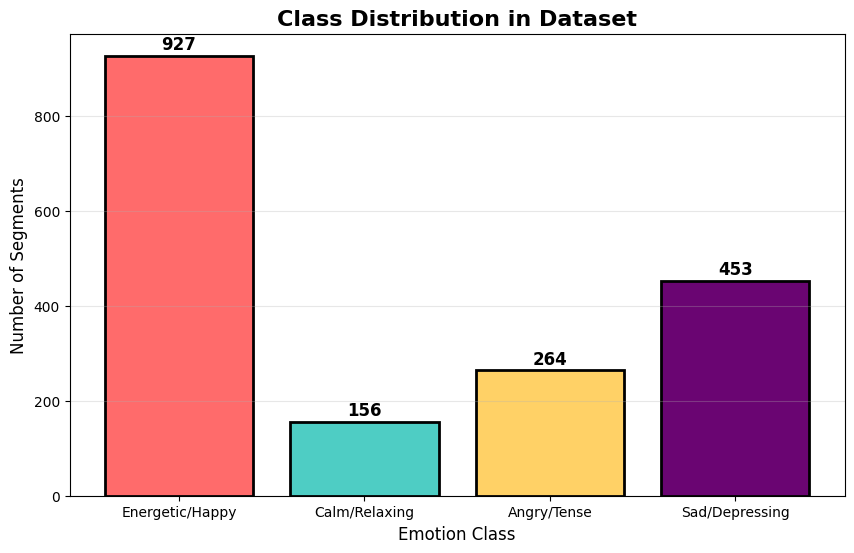


Visualizing features for sample segment...
✓ Saved feature visualization to /kaggle/working/feature_visualization.png


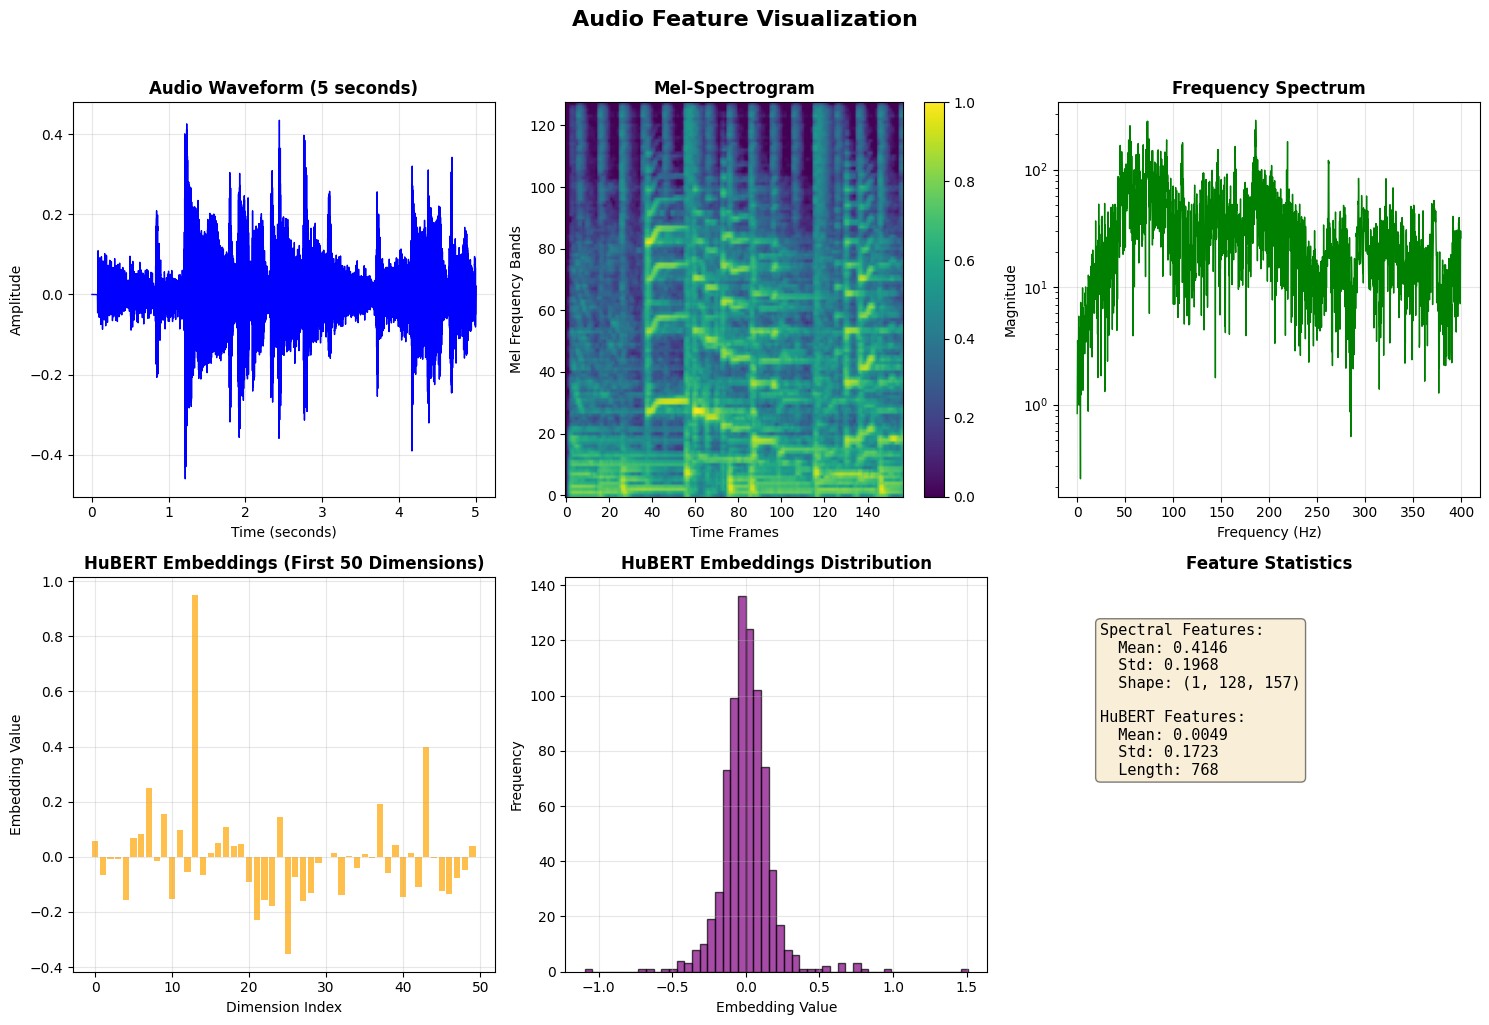


[STEP 9] SAVING RESULTS
----------------------------------------
✓ Test predictions saved to /kaggle/working/test_predictions.csv
✓ Training history saved to /kaggle/working/training_history.csv
✓ Model summary saved
✓ Final model saved to /kaggle/working/final_model.pth

🎉 PIPELINE COMPLETED SUCCESSFULLY!

📊 FINAL RESULTS:
   Test Accuracy: 79.44%
   Best Validation Accuracy: 82.22%
   Training Epochs: 30
   Model Parameters: 3,309,636

💾 Output saved to: /kaggle/working/

📁 Generated files:
   - .virtual_documents                  (   4.0 KB)
   - best_fusion_model.pth               (12958.4 KB)
   - class_distribution.png              (  48.0 KB)
   - confusion_matrix.png                (  70.7 KB)
   - feature_visualization.png           ( 293.6 KB)
   - final_model.pth                     (12959.5 KB)
   - model_summary.txt                   (   0.7 KB)
   - test_predictions.csv                (  12.0 KB)
   - training_history.csv                (   2.4 KB)
   - training_history.

In [74]:
# ============================================================================
# 9. MAIN PIPELINE
# ============================================================================

def run_complete_pipeline():
    """Run the complete pipeline"""
    
    print("\n" + "="*80)
    print("🎵 STARTING COMPLETE PIPELINE")
    print("="*80)
    
    # ========================================================================
    # STEP 1: LOAD DATA
    # ========================================================================
    print("\n[STEP 1] LOADING DATA")
    print("-" * 40)
    
    data_loader = DEAMDataLoader()
    segments, labels, valence, arousal, song_ids = data_loader.prepare_dataset(
        max_songs=Config.MAX_SONGS
    )
    
    if len(segments) == 0:
        print("❌ ERROR: No data loaded. Exiting.")
        return None
    
    print(f"✅ Loaded {len(segments)} segments")
    
    # ========================================================================
    # STEP 2: SPLIT DATA
    # ========================================================================
    print("\n[STEP 2] SPLITTING DATA")
    print("-" * 40)
    
    indices = np.arange(len(segments))
    
    # Train/Test split
    train_val_idx, test_idx = train_test_split(
        indices,
        test_size=Config.TEST_SIZE,
        random_state=42,
        stratify=labels
    )
    
    # Train/Validation split
    train_idx, val_idx = train_test_split(
        train_val_idx,
        test_size=Config.VAL_SIZE/(1-Config.TEST_SIZE),
        random_state=42,
        stratify=labels[train_val_idx]
    )
    
    print(f"Training samples: {len(train_idx)}")
    print(f"Validation samples: {len(val_idx)}")
    print(f"Test samples: {len(test_idx)}")
    
    # ========================================================================
    # STEP 3: INITIALIZE FEATURE EXTRACTOR
    # ========================================================================
    print("\n[STEP 3] INITIALIZING FEATURE EXTRACTOR")
    print("-" * 40)
    
    feature_extractor = FeatureExtractor()
    
    # ========================================================================
    # STEP 4: CREATE DATASETS
    # ========================================================================
    print("\n[STEP 4] CREATING DATASETS")
    print("-" * 40)
    
    print("Creating training dataset...")
    train_dataset = MusicEmotionDataset(
        segments[train_idx],
        labels[train_idx],
        feature_extractor,
        extract_features=True
    )
    
    print("Creating validation dataset...")
    val_dataset = MusicEmotionDataset(
        segments[val_idx],
        labels[val_idx],
        feature_extractor,
        extract_features=True
    )
    
    print("Creating test dataset...")
    test_dataset = MusicEmotionDataset(
        segments[test_idx],
        labels[test_idx],
        feature_extractor,
        extract_features=True
    )
    
    # Create dataloaders
    train_loader = DataLoader(train_dataset, batch_size=Config.BATCH_SIZE, 
                            shuffle=True, num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=Config.BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=Config.BATCH_SIZE,
                           shuffle=False, num_workers=2, pin_memory=True)
    
    print(f"\n✅ Dataloaders created:")
    print(f"   Training batches: {len(train_loader)}")
    print(f"   Validation batches: {len(val_loader)}")
    print(f"   Test batches: {len(test_loader)}")
    
    # ========================================================================
    # STEP 5: INITIALIZE MODEL
    # ========================================================================
    print("\n[STEP 5] INITIALIZING MODEL")
    print("-" * 40)
    
    model = FusionModel(num_classes=4)
    
    # Count parameters
    total_params, trainable_params = model.count_parameters()
    print(f"Total parameters: {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")
    
    # ========================================================================
    # STEP 6: TRAIN MODEL
    # ========================================================================
    print("\n[STEP 6] TRAINING MODEL")
    print("-" * 40)
    
    trainer = Trainer(model)
    optimizer = torch.optim.Adam(model.parameters(), lr=Config.LEARNING_RATE)
    
    # FIXED: Remove 'verbose' parameter from ReduceLROnPlateau
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', patience=5, factor=0.5
    )
    
    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': [],
        'learning_rate': []
    }
    
    best_val_acc = 0
    best_model_state = None
    
    print(f"\nStarting training for {Config.EPOCHS} epochs...")
    
    for epoch in range(Config.EPOCHS):
        print(f"\nEpoch {epoch + 1}/{Config.EPOCHS}")
        print("-" * 30)
        
        # Training
        train_loss, train_acc = trainer.train_epoch(train_loader, optimizer, epoch + 1)
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        
        # Validation
        val_loss, val_acc, _, _ = trainer.evaluate(val_loader)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        
        # Get current learning rate
        current_lr = optimizer.param_groups[0]['lr']
        history['learning_rate'].append(current_lr)
        
        # Update learning rate
        scheduler.step(val_loss)
        
        # Check if learning rate was reduced
        new_lr = optimizer.param_groups[0]['lr']
        if new_lr < current_lr:
            print(f"  Learning rate reduced: {current_lr:.6f} → {new_lr:.6f}")
        
        print(f"Training:   Loss = {train_loss:.4f}, Accuracy = {train_acc:.2f}%")
        print(f"Validation: Loss = {val_loss:.4f}, Accuracy = {val_acc:.2f}%")
        print(f"Learning Rate: {current_lr:.6f}")
        
        # Save best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_state = model.state_dict().copy()
            torch.save(best_model_state, Config.MODEL_SAVE_PATH)
            print(f"  🎯 New best model saved! (Validation Accuracy: {val_acc:.2f}%)")
    
    # Load best model
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
        print(f"\n✅ Loaded best model (Validation Accuracy: {best_val_acc:.2f}%)")
    
    # ========================================================================
    # STEP 7: EVALUATE MODEL
    # ========================================================================
    print("\n[STEP 7] EVALUATING MODEL")
    print("-" * 40)
    
    test_loss, test_acc, test_preds, test_labels = trainer.evaluate(test_loader)
    
    print(f"\n📊 TEST RESULTS:")
    print(f"   Loss: {test_loss:.4f}")
    print(f"   Accuracy: {test_acc:.2f}%")
    print(f"   Best Validation Accuracy: {best_val_acc:.2f}%")
    
    # Classification report
    print("\n📈 CLASSIFICATION REPORT:")
    print(classification_report(
        test_labels,
        test_preds,
        target_names=list(Config.EMOTION_MAP.values())
    ))
    
    # ========================================================================
    # STEP 8: VISUALIZE RESULTS
    # ========================================================================
    print("\n[STEP 8] VISUALIZING RESULTS")
    print("-" * 40)
    
    # Plot training history
    Visualizer.plot_training_history(
        history,
        save_path=os.path.join(Config.OUTPUT_DIR, 'training_history.png')
    )
    
    # Plot confusion matrix
    Visualizer.plot_confusion_matrix(
        test_labels,
        test_preds,
        save_path=os.path.join(Config.OUTPUT_DIR, 'confusion_matrix.png')
    )
    
    # Plot class distribution
    Visualizer.plot_class_distribution(
        labels,
        save_path=os.path.join(Config.OUTPUT_DIR, 'class_distribution.png')
    )
    
    # Visualize features
    if len(segments) > 0:
        sample_idx = 0
        print(f"\nVisualizing features for sample segment...")
        Visualizer.visualize_features(
            segments[sample_idx],
            feature_extractor,
            save_path=os.path.join(Config.OUTPUT_DIR, 'feature_visualization.png')
        )
    
    # ========================================================================
    # STEP 9: SAVE RESULTS
    # ========================================================================
    print("\n[STEP 9] SAVING RESULTS")
    print("-" * 40)
    
    # Save test predictions
    test_results = pd.DataFrame({
        'true_label': test_labels,
        'predicted_label': test_preds,
        'true_emotion': [Config.EMOTION_MAP[l] for l in test_labels],
        'predicted_emotion': [Config.EMOTION_MAP[p] for p in test_preds]
    })
    
    test_results_path = os.path.join(Config.OUTPUT_DIR, 'test_predictions.csv')
    test_results.to_csv(test_results_path, index=False)
    print(f"✓ Test predictions saved to {test_results_path}")
    
    # Save training history
    history_df = pd.DataFrame(history)
    history_path = os.path.join(Config.OUTPUT_DIR, 'training_history.csv')
    history_df.to_csv(history_path, index=False)
    print(f"✓ Training history saved to {history_path}")
    
    # Save model summary
    with open(os.path.join(Config.OUTPUT_DIR, 'model_summary.txt'), 'w') as f:
        f.write("=" * 60 + "\n")
        f.write("MUSIC EMOTION RECOGNITION MODEL - SUMMARY\n")
        f.write("=" * 60 + "\n\n")
        f.write("MODEL ARCHITECTURE:\n")
        f.write("  FusionModel (CNN + HuBERT)\n\n")
        f.write("MODEL PARAMETERS:\n")
        f.write(f"  Total parameters: {total_params:,}\n")
        f.write(f"  Trainable parameters: {trainable_params:,}\n\n")
        f.write("TRAINING RESULTS:\n")
        f.write(f"  Final Training Accuracy: {history['train_acc'][-1]:.2f}%\n")
        f.write(f"  Final Validation Accuracy: {history['val_acc'][-1]:.2f}%\n")
        f.write(f"  Best Validation Accuracy: {best_val_acc:.2f}%\n")
        f.write(f"  Test Accuracy: {test_acc:.2f}%\n\n")
        f.write("DATASET STATISTICS:\n")
        f.write(f"  Total songs processed: {Config.MAX_SONGS}\n")
        f.write(f"  Total segments: {len(segments)}\n")
        f.write(f"  Training samples: {len(train_idx)}\n")
        f.write(f"  Validation samples: {len(val_idx)}\n")
        f.write(f"  Test samples: {len(test_idx)}\n")
        f.write(f"  Class distribution:\n")
        unique, counts = np.unique(labels, return_counts=True)
        for label, count in zip(unique, counts):
            f.write(f"    {Config.EMOTION_MAP[label]}: {count}\n")
    
    print(f"✓ Model summary saved")
    
    # Save final model
    final_model_path = os.path.join(Config.OUTPUT_DIR, 'final_model.pth')
    torch.save({
        'model_state_dict': model.state_dict(),
        'config': {
            'sample_rate': Config.SAMPLE_RATE,
            'segment_duration': Config.SEGMENT_DURATION,
            'n_mels': Config.N_MELS,
            'emotion_map': Config.EMOTION_MAP
        },
        'test_accuracy': test_acc,
        'best_val_accuracy': best_val_acc
    }, final_model_path)
    
    print(f"✓ Final model saved to {final_model_path}")
    
    # ========================================================================
    # FINAL SUMMARY
    # ========================================================================
    print("\n" + "="*80)
    print("🎉 PIPELINE COMPLETED SUCCESSFULLY!")
    print("="*80)
    
    print(f"\n📊 FINAL RESULTS:")
    print(f"   Test Accuracy: {test_acc:.2f}%")
    print(f"   Best Validation Accuracy: {best_val_acc:.2f}%")
    print(f"   Training Epochs: {Config.EPOCHS}")
    print(f"   Model Parameters: {total_params:,}")
    
    print(f"\n💾 Output saved to: {Config.OUTPUT_DIR}")
    print("\n📁 Generated files:")
    for file in sorted(os.listdir(Config.OUTPUT_DIR)):
        file_path = os.path.join(Config.OUTPUT_DIR, file)
        file_size = os.path.getsize(file_path) / 1024
        print(f"   - {file:35} ({file_size:6.1f} KB)")
    
    return model, feature_extractor, test_acc

# ============================================================================
# 10. MAIN EXECUTION
# ============================================================================

if __name__ == "__main__":
    print("\n" + "="*80)
    print("🎵 MUSIC EMOTION RECOGNITION SYSTEM")
    print("Using Spectral Features + HuBERT Embeddings")
    print("="*80)
    
    # Check if in Kaggle
    is_kaggle = os.path.exists('/kaggle')
    if is_kaggle:
        print("\n📦 Detected Kaggle environment")
        print("Installing required packages...")
        
        # Install packages
        !pip install -q torch torchaudio librosa pandas numpy scikit-learn matplotlib seaborn transformers
    
    # Run the complete pipeline
    try:
        print("\n🚀 Starting complete pipeline...")
        result = run_complete_pipeline()
        
        if result:
            model, feature_extractor, accuracy = result
            print(f"\n✅ Pipeline completed with accuracy: {accuracy:.2f}%")
        else:
            print("\n⚠️ Pipeline completed with issues")
            
    except KeyboardInterrupt:
        print("\n\n⏹️ Pipeline interrupted by user")
        
    except Exception as e:
        print(f"\n❌ Error in pipeline execution: {e}")
        import traceback
        traceback.print_exc()